In [2]:
from pathlib import Path
from PIL import Image
import numpy as np

DATA_DIR = Path("../data")

images = []
labels = []

for subject_dir in sorted(DATA_DIR.iterdir()):
    if not subject_dir.is_dir():
        continue

    for image_path in sorted(subject_dir.iterdir()):
        try:
            image = Image.open(image_path).convert("L")  # grayscale
            pixels = np.asarray(image, dtype=np.uint8)

            images.append(pixels)
            labels.append(subject_dir.name)
        except (OSError, ValueError):
            # Skip files that are not readable images.
            continue

images = np.stack(images)
labels = np.asarray(labels)

print("Image array shape:", images.shape)
print("Number of images:", len(images))
print("Number of subjects:", len(np.unique(labels)))
print("First image dimensions:", images[0].shape)
print("Pixel intensity range:", images[0].min(), "to", images[0].max())

Image array shape: (400, 112, 92)
Number of images: 400
Number of subjects: 40
First image dimensions: (112, 92)
Pixel intensity range: 11 to 234


In [3]:
# Turn each 112 × 92 image into a vector of 10,304 pixel values.
X = images.reshape(len(images), -1)

print("Feature matrix shape:", X.shape)
print("Label array shape:", labels.shape)
print("First image vector length:", len(X[0]))
print("First 10 pixel values:", X[0, :10])

Feature matrix shape: (400, 10304)
Label array shape: (400,)
First image vector length: 10304
First 10 pixel values: [48 49 45 47 49 57 39 42 53 49]


In [4]:
from sklearn.model_selection import train_test_split
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels,
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Training subjects:", len(np.unique(y_train)))
print("Test subjects:", len(np.unique(y_test)))

Training shape: (320, 10304)
Test shape: (80, 10304)
Training subjects: 40
Test subjects: 40


In [5]:
# Mean pixel value at each position, computed from training images only.
mean_face = X_train.mean(axis=0)

# Center both sets using that same training mean.
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

print("Mean face vector shape:", mean_face.shape)
print("Centered training shape:", X_train_centered.shape)
print("Centered test shape:", X_test_centered.shape)
print("Training centered mean (should be near 0):",
      X_train_centered.mean())

Mean face vector shape: (10304,)
Centered training shape: (320, 10304)
Centered test shape: (80, 10304)
Training centered mean (should be near 0): -4.589841274475181e-16


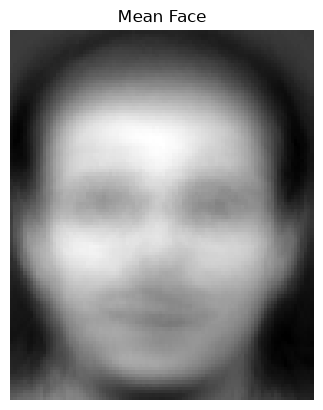

In [6]:
import matplotlib.pyplot as plt

mean_face_image = mean_face.reshape(images.shape[1:])

plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

In [7]:
# U: left singular vectors
# S: singular values
# Vt: principal directions (one direction per row)
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)

print("U shape:", U.shape)
print("S shape:", S.shape)
print("Vt shape:", Vt.shape)

U shape: (320, 320)
S shape: (320,)
Vt shape: (320, 10304)


In [8]:
# Variance associated with each principal component
explained_variance = S ** 2
explained_variance_ratio = explained_variance / explained_variance.sum()
cumulative_variance = np.cumsum(explained_variance_ratio)

# Minimum component count that reaches at least 90%
k_90 = np.searchsorted(cumulative_variance, 0.90) + 1

print("Components needed for at least 90% variance:", k_90)
print("Cumulative variance at that count:",
      cumulative_variance[k_90 - 1])

Components needed for at least 90% variance: 99
Cumulative variance at that count: 0.9008420546550728


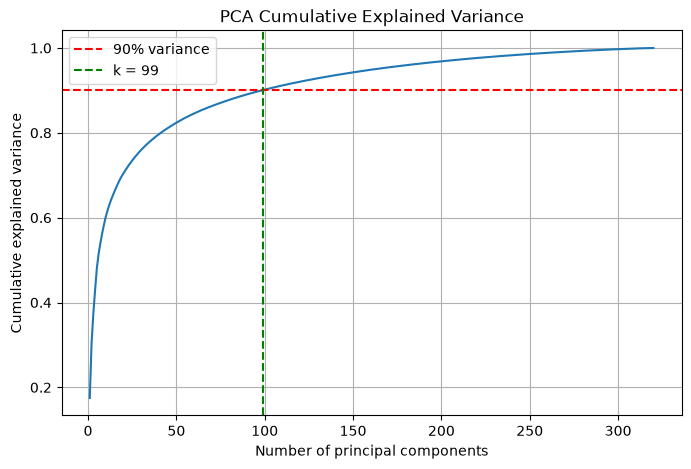

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance)
plt.axhline(0.90, color="red", linestyle="--", label="90% variance")
plt.axvline(k_90, color="green", linestyle="--", label=f"k = {k_90}")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA Cumulative Explained Variance")
plt.grid(True)
plt.legend()
plt.show()

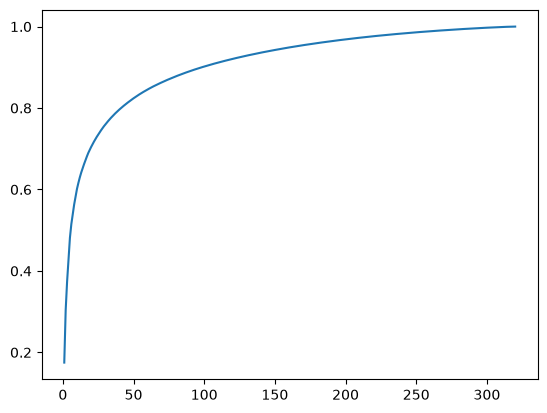

In [10]:
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance
)

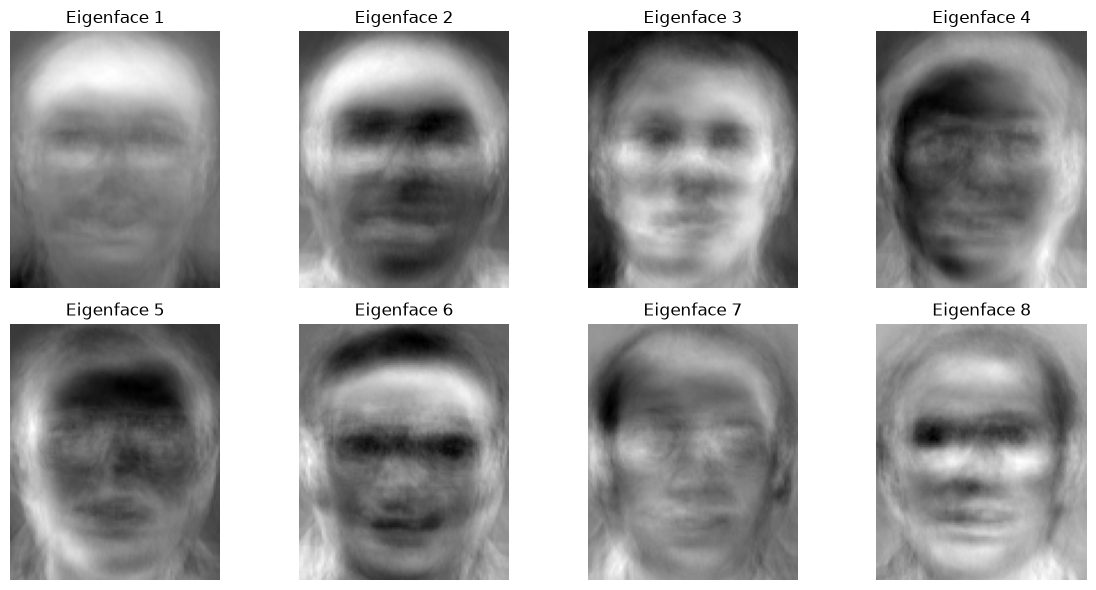

In [11]:
n_eigenfaces = 8

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    eigenface = Vt[i].reshape(images.shape[1:])
    ax.imshow(eigenface, cmap="gray")
    ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
# Covariance matrix in sample space (320 × 320)
cov_small = X_train_centered @ X_train_centered.T

# Symmetric eigendecomposition; sort largest eigenvalues first
eigvals_cov, eigvecs_cov = np.linalg.eigh(cov_small)
order = np.argsort(eigvals_cov)[::-1]
eigvals_cov = eigvals_cov[order]
eigvecs_cov = eigvecs_cov[:, order]

# Compare eigenvalues with squared singular values.
# They may differ by a constant factor if you used sample covariance (divide by n-1).
eigenvalue_relative_error = np.linalg.norm(
    eigvals_cov - S**2
) / np.linalg.norm(S**2)

# Compare directions by absolute cosine similarity; signs can differ.
cosine_similarity = np.abs(np.sum(eigvecs_cov[:, :10] * U[:, :10], axis=0))

print("Relative eigenvalue error:", eigenvalue_relative_error)
print("First 10 direction cosine similarities:", cosine_similarity)

Relative eigenvalue error: 2.3205098285019424e-15
First 10 direction cosine similarities: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [13]:
k = k_90
components = Vt[:k]  # shape: (99, 10304)

X_train_pca = X_train_centered @ components.T
X_test_pca = X_test_centered @ components.T

print("PCA components shape:", components.shape)
print("Reduced training shape:", X_train_pca.shape)
print("Reduced test shape:", X_test_pca.shape)

PCA components shape: (99, 10304)
Reduced training shape: (320, 99)
Reduced test shape: (80, 99)


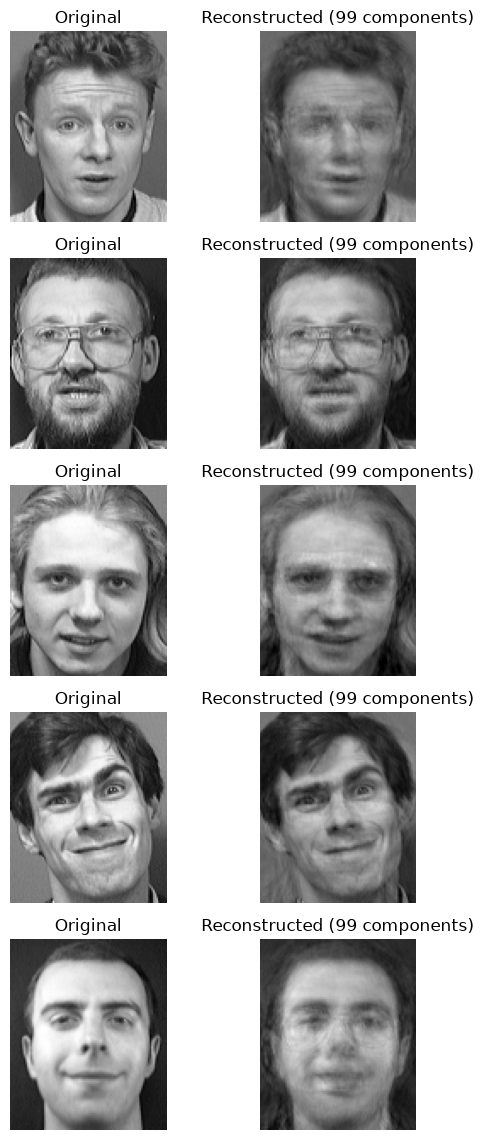

In [14]:
n_show = 5

reconstructed = X_train_pca[:n_show] @ components + mean_face
original = X_train[:n_show]

fig, axes = plt.subplots(n_show, 2, figsize=(6, 2.3 * n_show))

for i in range(n_show):
    axes[i, 0].imshow(original[i].reshape(images.shape[1:]), cmap="gray")
    axes[i, 0].set_title("Original")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(
        reconstructed[i].reshape(images.shape[1:]).clip(0, 255),
        cmap="gray",
        vmin=0,
        vmax=255,
    )
    axes[i, 1].set_title(f"Reconstructed ({k} components)")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [16]:
reconstructed_all = X_train_pca @ components + mean_face
mse_all = np.mean((X_train - reconstructed_all) ** 2)
print("Mean squared reconstruction error (all training images):", mse_all)

Mean squared reconstruction error (all training images): 154.2560270915595


In [17]:
# Euclidean distance from each test face to every training face
distances_pca = np.linalg.norm(
    X_test_pca[:, None, :] - X_train_pca[None, :, :],
    axis=2
)

nearest_train_idx = np.argmin(distances_pca, axis=1)
y_pred_pca = y_train[nearest_train_idx]

accuracy_pca = np.mean(y_pred_pca == y_test)
print(f"PCA nearest-face accuracy: {accuracy_pca:.3f} "
      f"({np.sum(y_pred_pca == y_test)}/{len(y_test)})")

PCA nearest-face accuracy: 0.988 (79/80)


In [19]:
correct_idx = np.flatnonzero(y_pred_pca == y_test)
incorrect_idx = np.flatnonzero(y_pred_pca != y_test)

print("Correct test indices:", correct_idx[:5])
print("Incorrect test indices:", incorrect_idx[:5])

for i in incorrect_idx[:5]:
    print(
        f"Test #{i}: true={y_test[i]}, predicted={y_pred_pca[i]}, "
        f"nearest training label={y_train[nearest_train_idx[i]]}"
    )

Correct test indices: [0 1 2 3 4]
Incorrect test indices: [9]
Test #9: true=s40, predicted=s5, nearest training label=s5


In [20]:
# Raw-pixel nearest-face baseline
distances_raw = np.linalg.norm(
    X_test[:, None, :] - X_train[None, :, :],
    axis=2
)
nearest_raw_idx = np.argmin(distances_raw, axis=1)
y_pred_raw = y_train[nearest_raw_idx]

print(
    f"Raw-pixel nearest-face accuracy: "
    f"{np.mean(y_pred_raw == y_test):.3f} "
    f"({np.sum(y_pred_raw == y_test)}/{len(y_test)})"
)

# Inspect PCA's incorrect match
incorrect_idx = np.flatnonzero(y_pred_pca != y_test)
for i in incorrect_idx:
    print(
        f"Test #{i}: true={y_test[i]}, predicted={y_pred_pca[i]}, "
        f"nearest training image index={nearest_train_idx[i]}"
    )

Raw-pixel nearest-face accuracy: 0.013 (1/80)
Test #9: true=s40, predicted=s5, nearest training image index=16


In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

classifiers = {
    "KNN (k=3)": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=3)
    ),
    "SVM (RBF)": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, gamma="scale")
    ),
}

for name, model in classifiers.items():
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)
    correct = np.sum(y_pred == y_test)
    print(f"{name}: {correct / len(y_test):.3f} ({correct}/{len(y_test)})")
    

KNN (k=3): 0.812 (65/80)
SVM (RBF): 0.963 (77/80)


In [22]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

component_counts = [25, 50, 75, 99, 125, 160]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tuning_results = []

for k_try in component_counts:
    Xtr = X_train_pca[:, :k_try]
    Xte = X_test_pca[:, :k_try]

    models_and_grids = {
        "KNN": (
            make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7]}
        ),
        "SVM": (
            make_pipeline(StandardScaler(), SVC(kernel="rbf")),
            {
                "svc__C": [1, 10, 100],
                "svc__gamma": ["scale", 0.001, 0.01]
            }
        ),
    }

    for name, (model, param_grid) in models_and_grids.items():
        search = GridSearchCV(
            model,
            param_grid,
            cv=cv,
            scoring="accuracy",
            n_jobs=-1
        )
        search.fit(Xtr, y_train)

        test_accuracy = search.score(Xte, y_test)
        tuning_results.append({
            "model": name,
            "components": k_try,
            "cv_accuracy": search.best_score_,
            "test_accuracy": test_accuracy,
            "best_settings": search.best_params_,
        })

for result in tuning_results:
    print(result)

{'model': 'KNN', 'components': 25, 'cv_accuracy': np.float64(0.95), 'test_accuracy': 0.95, 'best_settings': {'kneighborsclassifier__n_neighbors': 1}}
{'model': 'SVM', 'components': 25, 'cv_accuracy': np.float64(0.965625), 'test_accuracy': 0.9875, 'best_settings': {'svc__C': 100, 'svc__gamma': 0.001}}
{'model': 'KNN', 'components': 50, 'cv_accuracy': np.float64(0.93125), 'test_accuracy': 0.9375, 'best_settings': {'kneighborsclassifier__n_neighbors': 1}}
{'model': 'SVM', 'components': 50, 'cv_accuracy': np.float64(0.9625), 'test_accuracy': 0.975, 'best_settings': {'svc__C': 10, 'svc__gamma': 'scale'}}
{'model': 'KNN', 'components': 75, 'cv_accuracy': np.float64(0.8875), 'test_accuracy': 0.9375, 'best_settings': {'kneighborsclassifier__n_neighbors': 1}}
{'model': 'SVM', 'components': 75, 'cv_accuracy': np.float64(0.9375), 'test_accuracy': 0.9625, 'best_settings': {'svc__C': 10, 'svc__gamma': 0.01}}
{'model': 'KNN', 'components': 99, 'cv_accuracy': np.float64(0.840625), 'test_accuracy': 0.

In [23]:
original_values = images.shape[1] * images.shape[2]  # 10,304
compressed_values_99 = 99
compressed_values_25 = 25

print(f"Original values per image: {original_values}")
print(
    f"99-component values: {compressed_values_99} "
    f"({100 * compressed_values_99 / original_values:.2f}% of original; "
    f"{original_values / compressed_values_99:.1f}x smaller)"
)
print(
    f"25-component values: {compressed_values_25} "
    f"({100 * compressed_values_25 / original_values:.2f}% of original; "
    f"{original_values / compressed_values_25:.1f}x smaller)"
)


Original values per image: 10304
99-component values: 99 (0.96% of original; 104.1x smaller)
25-component values: 25 (0.24% of original; 412.2x smaller)


In [24]:
n_images = len(images)
n_pixels = images.shape[1] * images.shape[2]

for k_try in [99, 25]:
    # One shared basis and mean face, plus k coefficients per image
    pca_total_values = n_pixels * k_try + n_pixels + n_images * k_try
    original_total_values = n_images * n_pixels

    print(
        f"k={k_try}: total storage is "
        f"{pca_total_values / original_total_values:.1%} of original "
        f"({original_total_values / pca_total_values:.2f}x smaller)"
    )

k=99: total storage is 26.0% of original (3.85x smaller)
k=25: total storage is 6.7% of original (14.83x smaller)
